# Análisis numérico de descargas

Cada sección corresponde a una etapa del análisis (ver la tabla de etapas en `CLAUDE.md`).
Los métodos están en `metodos/` y las etapas, en `analisis/`; acá solo se llaman y se muestran los resultados.
Unidades internas: bytes y segundos. 1 MB = 10⁶ B.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from analisis.preparacion import cargar_corrida, preparar_corrida

corridas = pd.read_csv("datos/corridas.csv")
corridas[["corrida", "banda", "ubicacion", "carga_extra", "tamano_bytes", "senal_dbm", "wget_vel"]]

,corrida,banda,ubicacion,carga_extra,tamano_bytes,senal_dbm,wget_vel
0,C1,5 GHz,cerca del router (4 m),ninguna,2927861760,-54.0,NaN
1,C2,5 GHz,cerca del router (4 m),Netflix en el TV,2927861760,-55.0,10.2 MB/s
2,C3,2.4 GHz,cerca del router (4 m),ninguna,2927861760,-42.0,8.53 MB/s
3,C4,2.4 GHz,"balcón (6 m), puerta cerrada",ninguna,2927861760,NaN,4.30 MB/s


## Etapa 0: preparación

Para cada corrida:
1. `B(t) = C(t) − C(t₀)`, con `C` el contador del sistema.
2. Tasa de fondo `r_f`: pendiente por mínimos cuadrados en los primeros y en los últimos 30 s (cada tramo por separado, se promedian).
3. Bytes de la descarga: `B_d(t) = B(t) − r_f·t`.
4. `v∞`: pendiente de `B_d` entre el 20 % y el 80 % de los bytes.
5. `v = dB_d/dt` con la fórmula de 3 puntos; `t_ini` y `t_fin` son el primer y el último instante con `v > 0,1·v∞`.
6. Sobrecarga de protocolo: `p = (B_d(t_fin) − S) / S`.

In [2]:
resultados = {}
for _, fila in corridas.iterrows():
    t, B = cargar_corrida(f"datos/{fila.corrida.lower()}.csv")
    resultados[fila.corrida] = {"t": t, "B": B, "S": fila.tamano_bytes,
                                **preparar_corrida(t, B, fila.tamano_bytes)}

tabla = pd.DataFrame({
    c: {
        "h medio [s]": r["h"],
        "desvío de h [s]": r["desvio_h"],
        "r_f inicio [B/s]": r["r_inicio"],
        "r_f final [B/s]": r["r_final"],
        "r_f [B/s]": r["r_f"],
        "v∞ [MB/s]": r["v_inf"] / 1e6,
        "t_ini [s]": r["t_ini"],
        "t_fin [s]": r["t_fin"],
        "duración [s]": r["t_fin"] - r["t_ini"],
        "B_d(t_fin) [B]": r["B_d"][r["i_fin"]],
        "p [%]": 100 * r["p"],
    }
    for c, r in resultados.items()
})
tabla.style.format("{:.6g}")

,C1,C2,C3,C4
h medio [s],0.1,0.1,0.1,0.1
desvío de h [s],7.92502e-05,8.20781e-05,0.000110703,7.6824e-05
r_f inicio [B/s],737.467,1021.86,689.983,278.932
r_f final [B/s],1118.65,217.501,1081.78,576.205
r_f [B/s],928.06,619.682,885.882,427.568
v∞ [MB/s],11.5788,11.2702,9.43216,4.67295
t_ini [s],32.6001,35.6001,34.9001,33.7003
t_fin [s],299,309.4,361.5,682.2
duración [s],266.4,273.8,326.6,648.5
B_d(t_fin) [B],3.07638e+09,3.07582e+09,3.07469e+09,3.07473e+09


### Control contra `wget`

`wget` informa la velocidad media de toda la descarga, `S / duración`, en unidades de 2²⁰ B aunque diga "MB/s".
Si la duración medida es correcta, las dos columnas tienen que coincidir. (C1 no tiene el dato.)

In [3]:
pd.DataFrame({
    "S / duración [MiB/s]": {c: r["S"] / (r["t_fin"] - r["t_ini"]) / 2**20 for c, r in resultados.items()},
    "wget": corridas.set_index("corrida")["wget_vel"],
})

,S / duración [MiB/s],wget
C1,10.481331,NaN
C2,10.198044,10.2 MB/s
C3,8.549373,8.53 MB/s
C4,4.305669,4.30 MB/s


### Bytes de la descarga en cada corrida

Las líneas punteadas marcan `t_ini` y `t_fin`. Mismo eje vertical en las cuatro, para comparar.

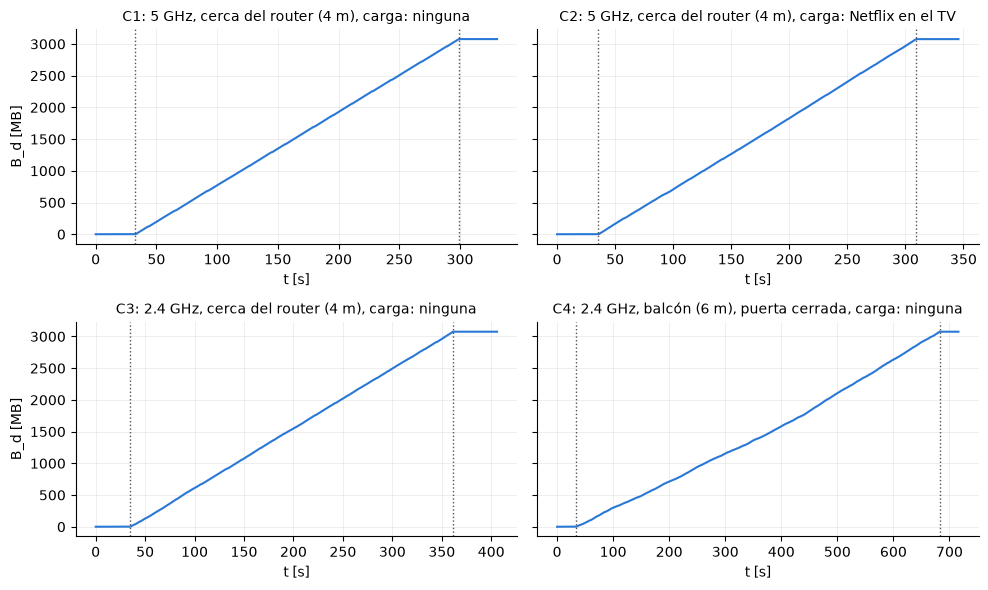

In [4]:
fig, ejes = plt.subplots(2, 2, figsize=(10, 6), sharey=True)
for eje, (c, r) in zip(ejes.flat, resultados.items()):
    eje.plot(r["t"], r["B_d"] / 1e6, color="#2a78d6", linewidth=1.5)
    for t_marca in (r["t_ini"], r["t_fin"]):
        eje.axvline(t_marca, color="#52514e", linewidth=1, linestyle=":")
    fila = corridas.set_index("corrida").loc[c]
    eje.set_title(f"{c}: {fila.banda}, {fila.ubicacion}, carga: {fila.carga_extra}", fontsize=10)
    eje.set_xlabel("t [s]")
    eje.grid(alpha=0.3, linewidth=0.5)
    eje.spines[["top", "right"]].set_visible(False)
for eje in ejes[:, 0]:
    eje.set_ylabel("B_d [MB]")
fig.tight_layout()

## Etapa 1: velocímetro

`v = dB_d/dt` con las fórmulas de 3 y de 5 puntos, con el paso de la captura (h = 0,1 s) y con h = 1 s (una lectura de cada 10).
La referencia es `v∞` de la etapa 0. En el tramo de régimen (entre el 20 % y el 80 % de los bytes) se mide:
- **media** de `v − v∞`: si el velocímetro está corrido;
- **desvío** de `v − v∞`: cuánto oscila la lectura de una muestra a otra.

Si las diferencias fueran solo ruido de medición en B (blanco, de desvío σ), el desvío de v sería 0,71·σ/h con 3 puntos y 0,95·σ/h con 5 puntos (ver `tests/test_velocimetro.py`): pasar de h = 0,1 a 1 s lo dividiría por 10, y 5 puntos daría un 34 % más que 3 puntos.

In [5]:
from analisis.velocimetro import velocidades, error_en_regimen

filas = []
for c, r in resultados.items():
    for k in (1, 10):
        vel = velocidades(r["t"], r["B_d"], k)
        for formula in ("v3", "v5"):
            media, desvio = error_en_regimen(vel[formula], r["v_inf"], vel["B_d"])
            filas.append({
                "corrida": c,
                "h [s]": round(vel["h"], 3),
                "fórmula": "3 puntos" if formula == "v3" else "5 puntos",
                "media [MB/s]": media / 1e6,
                "desvío [MB/s]": desvio / 1e6,
                "desvío / v∞ [%]": 100 * desvio / r["v_inf"],
            })
velocimetro = pd.DataFrame(filas)
velocimetro.pivot(index="corrida", columns=["h [s]", "fórmula"],
                  values=["media [MB/s]", "desvío [MB/s]", "desvío / v∞ [%]"]).round(3)

media [MB/s]                            desvío [MB/s]           \
h [s]            0.1               1.0                    0.1            
fórmula     3 puntos 5 puntos 3 puntos 5 puntos      3 puntos 5 puntos   
corrida                                                                  
C1            -0.051   -0.052   -0.052   -0.052         1.938    2.079   
C2            -0.022   -0.022   -0.026   -0.028         2.016    2.213   
C3            -0.022   -0.022   -0.016   -0.016         2.183    2.451   
C4             0.058    0.058    0.058    0.057         1.479    1.591   

                          desvío / v∞ [%]                             
h [s]        1.0                      0.1               1.0           
fórmula 3 puntos 5 puntos        3 puntos 5 puntos 3 puntos 5 puntos  
corrida                                                               
C1         0.927    1.088          16.735   17.958    8.006    9.398  
C2         0.929    1.080          17.890   19.632    8.246    9.584  
C3         0.949    1.119          23.144   25.982   10.064   11.861  
C4         0.919    0.985          31.652   34.053   19.656   21.074

In [6]:
# Cuánto cambia el desvío: al pasar de h = 0,1 a 1 s, y de 3 a 5 puntos.
d = velocimetro.set_index(["corrida", "h [s]", "fórmula"])["desvío [MB/s]"].unstack(["h [s]", "fórmula"])
pd.DataFrame({
    "h 0,1 → 1 s (3 p.)": d[(0.1, "3 puntos")] / d[(1.0, "3 puntos")],
    "h 0,1 → 1 s (5 p.)": d[(0.1, "5 puntos")] / d[(1.0, "5 puntos")],
    "5 p. / 3 p. (h = 0,1)": d[(0.1, "5 puntos")] / d[(0.1, "3 puntos")],
    "5 p. / 3 p. (h = 1)": d[(1.0, "5 puntos")] / d[(1.0, "3 puntos")],
}).round(2)

,"h 0,1 → 1 s (3 p.)","h 0,1 → 1 s (5 p.)","5 p. / 3 p. (h = 0,1)",5 p. / 3 p. (h = 1)
corrida,,,,
C1,2.09,1.91,1.07,1.17
C2,2.17,2.05,1.10,1.16
C3,2.30,2.19,1.12,1.18
C4,1.61,1.62,1.08,1.07


### Velocímetro de C1 en un minuto de régimen

Las cuatro combinaciones en la misma escala vertical. La línea punteada es `v∞`.

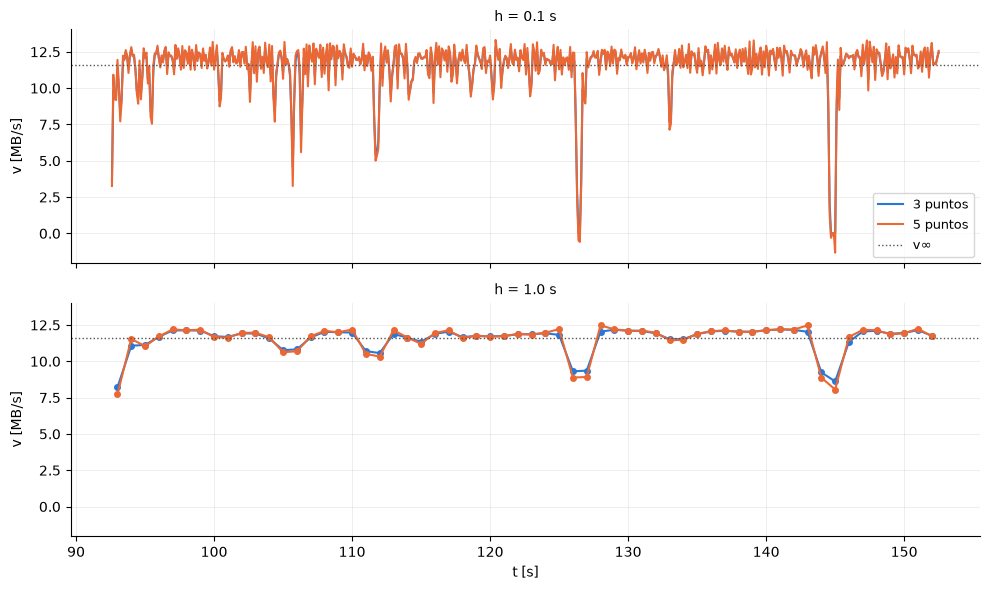

In [7]:
r = resultados["C1"]
desde, hasta = r["t_ini"] + 60, r["t_ini"] + 120

fig, ejes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, sharey=True)
for eje, k in zip(ejes, (1, 10)):
    vel = velocidades(r["t"], r["B_d"], k)
    ventana = (vel["t"] >= desde) & (vel["t"] <= hasta)
    marcador = "o" if k > 1 else None
    eje.plot(vel["t"][ventana], vel["v3"][ventana] / 1e6, color="#2a78d6", linewidth=1.5,
             marker=marcador, markersize=4, label="3 puntos")
    eje.plot(vel["t"][ventana], vel["v5"][ventana] / 1e6, color="#eb6834", linewidth=1.5,
             marker=marcador, markersize=4, label="5 puntos")
    eje.axhline(r["v_inf"] / 1e6, color="#52514e", linewidth=1, linestyle=":", label="v∞")
    eje.set_title(f"h = {vel['h']:.1f} s", fontsize=10)
    eje.set_ylabel("v [MB/s]")
    eje.grid(alpha=0.3, linewidth=0.5)
    eje.spines[["top", "right"]].set_visible(False)
ejes[0].legend(loc="lower right", fontsize=9)
ejes[-1].set_xlabel("t [s]")
fig.tight_layout()

### Caídas de velocidad en régimen

Con h = 0,1 s y 3 puntos: mediana de v y porcentaje de lecturas por debajo de 0,5·v∞ y de 0,9·v∞.

In [8]:
from analisis.preparacion import tramo_regimen

caidas = {}
for c, r in resultados.items():
    vel = velocidades(r["t"], r["B_d"])
    v = vel["v3"][tramo_regimen(vel["B_d"])]
    caidas[c] = {
        "v∞ [MB/s]": r["v_inf"] / 1e6,
        "mediana de v [MB/s]": np.median(v) / 1e6,
        "v < 0,5·v∞ [%]": 100 * np.mean(v < 0.5 * r["v_inf"]),
        "v < 0,9·v∞ [%]": 100 * np.mean(v < 0.9 * r["v_inf"]),
    }
pd.DataFrame(caidas).T.round(2)

,v∞ [MB/s],mediana de v [MB/s],"v < 0,5·v∞ [%]","v < 0,9·v∞ [%]"
C1,11.58,12.00,2.75,8.43
C2,11.27,11.81,3.23,11.71
C3,9.43,10.06,4.54,19.74
C4,4.67,4.90,6.51,30.72


### Qué muestra la etapa 1

- **Sin sesgo.** La media de `v − v∞` es menor al 1 % de v∞ en las cuatro corridas y con las cuatro combinaciones. Es lo esperable: el promedio de la derivada en un tramo es (casi) la pendiente media de B_d en ese tramo.
- **El desvío no es ruido de medición.** Con h = 1 s el desvío baja, pero de 1,6 a 2,3 veces y no 10, y 5 puntos da entre un 7 y un 18 % más que 3 puntos, no un 34 %. El modelo de ruido blanco en B no describe estos datos.
- **Lo que se ve son caídas reales.** La velocidad pasa casi todo el tiempo un poco por encima de v∞ y cada tanto cae durante unas décimas de segundo, a veces hasta 0: la descarga se frena de verdad (Wi-Fi, TCP). Por eso la mediana de v supera a v∞, que es la velocidad *media* e incluye las caídas. Con h = 1 s cada caída se promedia con el resto del segundo y se ve atenuada.
- **Más caídas con peor enlace.** El porcentaje de lecturas bajo 0,9·v∞ crece de C1 a C2, a C3 y a C4, en el mismo orden en que baja v∞.
- **3 puntos con h = 1 s es la combinación de menor desvío en las cuatro corridas.** El orden más alto de 5 puntos solo ayuda si B es suave; acá no lo es, y sus coeficientes más grandes amplifican más las variaciones. El orden teórico de cada fórmula se verifica en `tests/test_derivacion.py`, con funciones de derivada exacta conocida.

## Etapa 2: volumen desde la velocidad

Un sistema que solo ve el velocímetro cada H segundos estima los bytes descargados como `D = ∫ v dt`, por trapecios o por Simpson.
Se usa la velocidad de la etapa 0 (3 puntos, h = 0,1 s).

- **Muestras:** una cada k = H/h lecturas. La última cae en `t_fin` (o unas décimas después, ver desfase) y las demás van hacia atrás de a H hasta pasar `t_ini`. Así el paso es uniforme y la integral cubre toda la descarga.
- **Referencia:** lo que marcó el contador en el mismo intervalo, `B_d(t_b) − B_d(t_a)`.
- **Desfase:** con H = 1 s hay 10 formas de elegir las muestras (corridas de a 0,1 s). Como v tiene caídas cortas (etapa 1), una muestra puede caer o no en una caída. Se prueban las 10.

### Control: todas las muestras (H = h)

Trapecios sobre la derivada de 3 puntos telescopa: `Σ (B_{i+1} − B_{i−1})/2 ≈ B_b − B_a`. Tiene que recuperar la referencia salvo los extremos. Es un control del código, no una medida de precisión.

In [9]:
from analisis.volumen import volumen_desde_velocidad

control = {}
for c, r in resultados.items():
    vol = volumen_desde_velocidad(r["t"], r["v"], r["B_d"], r["i_ini"], r["i_fin"], k=1)
    control[c] = {
        "referencia [MB]": vol["referencia"] / 1e6,
        "trapecios [MB]": vol["trapecios"] / 1e6,
        "Simpson [MB]": vol["simpson"] / 1e6,
        "error trapecios [%]": 100 * (vol["trapecios"] - vol["referencia"]) / vol["referencia"],
        "error Simpson [%]": 100 * (vol["simpson"] - vol["referencia"]) / vol["referencia"],
    }
pd.DataFrame(control).T.style.format("{:.4f}")

,referencia [MB],trapecios [MB],Simpson [MB],error trapecios [%],error Simpson [%]
C1,3075.9987,3075.6427,3075.7604,-0.0116,-0.0077
C2,3075.3704,3075.2702,3075.3040,-0.0033,-0.0022
C3,3074.2854,3074.1352,3074.1851,-0.0049,-0.0033
C4,3074.5585,3074.5098,3074.5506,-0.0016,-0.0003


### Muestras cada H = 1 s

Error relativo `(D − referencia) / referencia` para los 10 desfases.

In [10]:
filas = []
for c, r in resultados.items():
    for desfase in range(10):
        vol = volumen_desde_velocidad(r["t"], r["v"], r["B_d"], r["i_ini"], r["i_fin"], k=10, desfase=desfase)
        for metodo in ("trapecios", "simpson"):
            filas.append({
                "corrida": c,
                "desfase [s]": round(desfase * r["h"], 1),
                "método": "trapecios" if metodo == "trapecios" else "Simpson",
                "D [B]": vol[metodo],
                "referencia [B]": vol["referencia"],
                "error [%]": 100 * (vol[metodo] - vol["referencia"]) / vol["referencia"],
            })
volumen = pd.DataFrame(filas)

resumen = volumen.groupby(["corrida", "método"])["error [%]"].agg(
    desfase_0=lambda e: e.iloc[0],
    mínimo="min",
    máximo="max",
    promedio="mean",
    desvío="std",
)
resumen.round(3)

desfase_0  mínimo  máximo  promedio  desvío
corrida método                                                
C1      Simpson        0.743  -0.880   1.238     0.261   0.549
        trapecios      0.478  -1.219   0.780    -0.018   0.535
C2      Simpson       -0.551  -1.390   1.749     0.082   1.110
        trapecios     -0.584  -1.470   1.635    -0.007   1.037
C3      Simpson       -0.256  -0.264   1.080     0.511   0.454
        trapecios     -0.734  -0.734   0.636    -0.008   0.450
C4      Simpson       -0.371  -1.204   1.669     0.186   1.009
        trapecios     -0.012  -1.768   1.755    -0.003   1.253

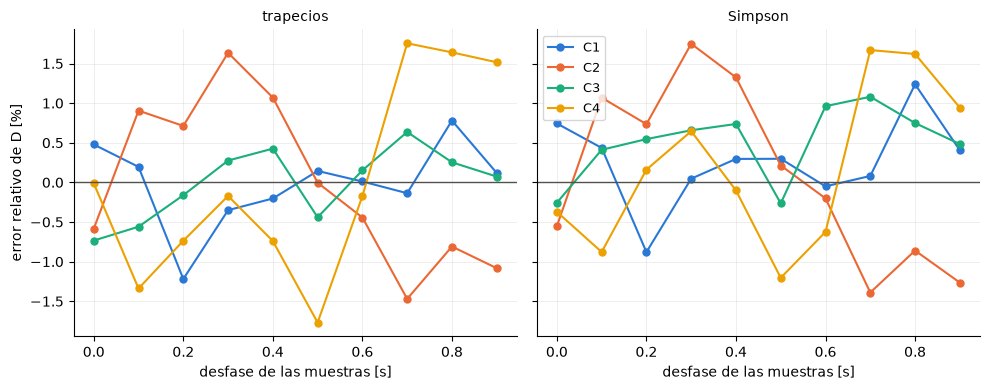

In [11]:
colores = {"C1": "#2a78d6", "C2": "#eb6834", "C3": "#1baf7a", "C4": "#eda100"}

fig, ejes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for eje, metodo in zip(ejes, ("trapecios", "Simpson")):
    for c in resultados:
        datos = volumen[(volumen["corrida"] == c) & (volumen["método"] == metodo)]
        eje.plot(datos["desfase [s]"], datos["error [%]"], color=colores[c],
                 linewidth=1.5, marker="o", markersize=5, label=c)
    eje.axhline(0, color="#52514e", linewidth=1)
    eje.set_title(metodo, fontsize=10)
    eje.set_xlabel("desfase de las muestras [s]")
    eje.grid(alpha=0.3, linewidth=0.5)
    eje.spines[["top", "right"]].set_visible(False)
ejes[0].set_ylabel("error relativo de D [%]")
ejes[1].legend(fontsize=9)
fig.tight_layout()

### Sobrecarga estimada con D

Si el sistema calcula la sobrecarga con su estimación D en lugar del contador: `p = (D − S) / S`.
La columna "contador" es la misma cuenta con la referencia del mismo intervalo (difiere de la etapa 0 en los bytes antes de `t_a`, menos de 0,02 puntos).

In [12]:
S = volumen["corrida"].map({c: r["S"] for c, r in resultados.items()})
volumen["p [%]"] = 100 * (volumen["D [B]"] - S) / S
volumen["p contador [%]"] = 100 * (volumen["referencia [B]"] - S) / S

sobrecargas = volumen.groupby(["corrida", "método"])["p [%]"].agg(["min", "max"]).unstack("método")
sobrecargas.columns = [f"p {metodo}, {extremo} [%]" for extremo, metodo in sobrecargas.columns]
sobrecargas.insert(0, "p contador [%]", volumen.groupby("corrida")["p contador [%]"].first())
sobrecargas.insert(0, "p etapa 0 [%]", pd.Series({c: 100 * r["p"] for c, r in resultados.items()}))
sobrecargas[["p etapa 0 [%]", "p contador [%]", "p trapecios, min [%]", "p trapecios, max [%]",
             "p Simpson, min [%]", "p Simpson, max [%]"]].round(2)

,p etapa 0 [%],p contador [%],"p trapecios, min [%]","p trapecios, max [%]","p Simpson, min [%]","p Simpson, max [%]"
corrida,,,,,,
C1,5.07,5.07,3.79,5.90,4.15,6.38
C2,5.05,5.05,3.51,6.77,3.59,6.89
C3,5.01,5.01,4.24,5.68,4.74,6.15
C4,5.02,5.02,3.15,6.86,3.75,6.77


### Qué muestra la etapa 2

- **Control.** Con todas las muestras, trapecios recupera la referencia con error menor a 0,012 % en las cuatro corridas: es el telescopado, no precisión del método.
- **Con H = 1 s el error es de hasta ±1,8 %**, y su signo depende del desfase: según dónde caigan las muestras, se pierden o se cuentan de más las caídas cortas de velocidad que se vieron en la etapa 1. Con 3 GB, 1 % son unos 30 MB.
- **Simpson no mejora a trapecios.** Su error O(H⁴) supone una v suave, con derivadas acotadas; acá v tiene caídas más cortas que H, y el error lo domina el muestreo, no el truncamiento. Además, los pesos 4-2-4 de Simpson le dan el doble de peso a la mitad de las muestras, lo que no ayuda a promediar.
- **Promedio de los 10 desfases.** En trapecios es prácticamente 0: los 10 desfases juntos usan todas las lecturas, que es el control. En Simpson queda un promedio positivo de 0,1 a 0,5 %.
- **Sobrecarga.** Con el contador, p ≈ 5 %. Con D, según el desfase, p va de 3,2 a 6,9 %: el error de integración es del mismo orden que la sobrecarga que se quiere medir. Para medir p hace falta el contador, no el velocímetro.

## Etapa 3: efecto del muestreo

La integración de la etapa 2 con muestras cada H = 1, 5, 10 y 30 s (k = 10, 50, 100 y 300 lecturas).
Como el error depende del desfase, para cada H se prueban los k desfases y se resume con el **error cuadrático medio** (ECM) y el **máximo**.

Con una función suave, el error de trapecios crecería como H² y el de Simpson como H⁴: en log-log, pendientes 2 y 4.
La pendiente observada se calcula por regresión lineal sobre `ln(ECM)` contra `ln(H)`.

Se hace dos veces:
- **descarga completa**, de `t_ini` a `t_fin`, como en la etapa 2;
- **solo régimen** (entre el 20 % y el 80 % de los bytes): sin el arranque ni el corte final, donde v salta. Sirve para ver si el error viene de esos saltos o de las caídas de v.

In [13]:
from analisis.preparacion import tramo_regimen
from analisis.volumen import errores_por_desfase
from metodos.regresion import regresion_lineal

pasos_H = {1: 10, 5: 50, 10: 100, 30: 300}   # H [s] → k lecturas

filas = []
for c, r in resultados.items():
    regimen = np.nonzero(tramo_regimen(r["B_d"]))[0]
    tramos = {"descarga completa": (r["i_ini"], r["i_fin"]),
              "solo régimen": (regimen[0], regimen[-1])}
    for tramo, (i_a, i_b) in tramos.items():
        for H, k in pasos_H.items():
            errores = errores_por_desfase(r["t"], r["v"], r["B_d"], i_a, i_b, k)
            for metodo, e in errores.items():
                filas.append({
                    "corrida": c,
                    "tramo": tramo,
                    "método": "trapecios" if metodo == "trapecios" else "Simpson",
                    "H [s]": H,
                    "ECM [%]": 100 * np.sqrt(np.mean(e**2)),
                    "máximo [%]": 100 * np.max(np.abs(e)),
                    "promedio [%]": 100 * np.mean(e),
                })
muestreo = pd.DataFrame(filas)

completa = muestreo[muestreo["tramo"] == "descarga completa"]
completa.pivot(index=["corrida", "método"], columns="H [s]", values=["ECM [%]", "máximo [%]"]).round(2)

ECM [%]                   máximo [%]                    
H [s]                  1     5     10    30         1     5      10     30
corrida método                                                            
C1      Simpson      0.58  1.92  3.42  8.32       1.24  4.96   6.74  24.24
        trapecios    0.51  1.50  2.88  7.03       1.22  4.11   6.67  22.23
C2      Simpson      1.06  2.32  3.63  7.62       1.75  5.63   8.21  22.17
        trapecios    0.98  2.21  3.64  7.33       1.64  5.97   8.13  30.13
C3      Simpson      0.67  3.03  4.53  8.68       1.08  7.65  10.69  28.47
        trapecios    0.43  2.75  4.33  7.88       0.73  6.29  10.81  34.64
C4      Simpson      0.97  2.72  3.87  6.78       1.67  6.14   9.30  17.92
        trapecios    1.19  2.42  3.74  6.06       1.77  5.88   8.35  18.57

### Pendiente en log-log

In [14]:
def pendiente(datos):
    _, b = regresion_lineal(np.log(datos["H [s]"]), np.log(datos["ECM [%]"]))
    return b

muestreo.groupby(["corrida", "método", "tramo"])[["H [s]", "ECM [%]"]].apply(pendiente) \
    .unstack("tramo").round(2)

tramo              descarga completa  solo régimen
corrida método                                    
C1      Simpson                 0.78          0.63
        trapecios               0.77          0.72
C2      Simpson                 0.58          0.55
        trapecios               0.59          0.55
C3      Simpson                 0.76          0.65
        trapecios               0.87          0.59
C4      Simpson                 0.57          0.54
        trapecios               0.48          0.61

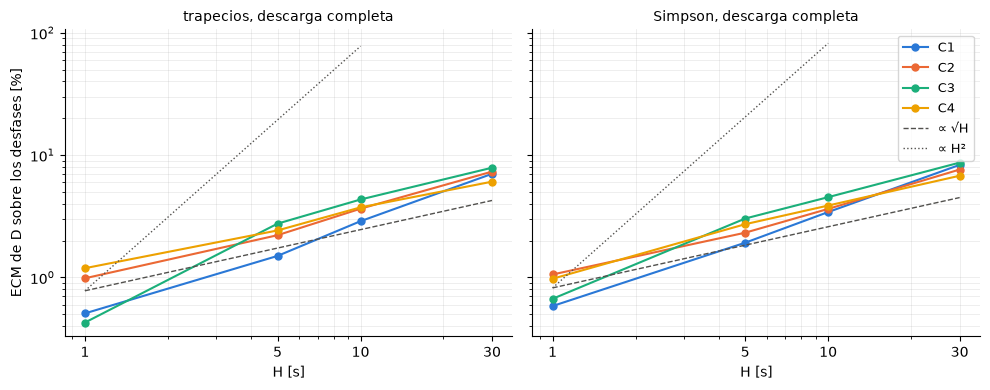

In [15]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
H_guia = np.array(list(pasos_H))
for eje, metodo in zip(ejes, ("trapecios", "Simpson")):
    for c in resultados:
        datos = completa[(completa["corrida"] == c) & (completa["método"] == metodo)]
        eje.loglog(datos["H [s]"], datos["ECM [%]"], color=colores[c],
                   linewidth=1.5, marker="o", markersize=5, label=c)
    # Guías: pendiente 1/2 y pendiente 2 (trapecios teórico), desde H = 1 s
    ecm_1 = completa[(completa["método"] == metodo) & (completa["H [s]"] == 1)]["ECM [%]"].mean()
    eje.loglog(H_guia, ecm_1 * H_guia**0.5, color="#52514e", linewidth=1, linestyle="--", label="∝ √H")
    eje.loglog(H_guia[:3], ecm_1 * H_guia[:3]**2, color="#52514e", linewidth=1, linestyle=":", label="∝ H²")
    eje.set_title(f"{metodo}, descarga completa", fontsize=10)
    eje.set_xlabel("H [s]")
    eje.set_xticks(H_guia, [str(H) for H in H_guia])
    eje.grid(alpha=0.3, linewidth=0.5, which="both")
    eje.spines[["top", "right"]].set_visible(False)
ejes[0].set_ylabel("ECM de D sobre los desfases [%]")
ejes[1].legend(fontsize=9)
fig.tight_layout()

### Sesgo de Simpson en los bordes

Promedio del error sobre los desfases. Si v fuera una caja (0 antes de `t_ini` y después de `t_fin`, v∞ entre medio), Simpson daría H·v∞/3 de más con n par y H·v∞/6 con n impar (último intervalo por trapecios); ver `test_simpson_sobreestima_una_caja`. En relativo, para una caja ideal, a lo sumo `H / (3·duración)`. Trapecios no tiene ese sesgo.

In [16]:
promedios = muestreo[muestreo["método"] == "Simpson"].pivot(
    index=["corrida", "H [s]"], columns="tramo", values="promedio [%]")
promedios.columns = [f"Simpson, {tramo} [%]" for tramo in promedios.columns]
promedios["trapecios, descarga completa [%]"] = muestreo[
    (muestreo["método"] == "trapecios") & (muestreo["tramo"] == "descarga completa")
].set_index(["corrida", "H [s]"])["promedio [%]"]
duracion = pd.Series({c: r["t_fin"] - r["t_ini"] for c, r in resultados.items()})
promedios["H / (3·duración) [%]"] = [100 * H / (3 * duracion[c]) for c, H in promedios.index]
promedios.round(2)

Simpson, descarga completa [%]  Simpson, solo régimen [%]  \
corrida H [s]                                                              
C1      1                                0.26                      -0.14   
        5                                0.22                       0.26   
        10                               1.36                      -0.27   
        30                               3.58                      -0.13   
C2      1                                0.08                       0.18   
        5                                0.50                      -0.07   
        10                               0.97                      -0.38   
        30                               3.53                      -0.10   
C3      1                                0.51                       0.42   
        5                                0.72                      -0.06   
        10                               1.07                      -0.09   
        30                               2.88                      -0.00   
C4      1                                0.19                      -0.16   
        5                                0.58                      -0.39   
        10                               0.40                       0.43   
        30                               0.95                      -0.50   

               trapecios, descarga completa [%]  H / (3·duración) [%]  
corrida H [s]                                                          
C1      1                                 -0.02                  0.13  
        5                                 -0.02                  0.63  
        10                                -0.02                  1.25  
        30                                -0.02                  3.75  
C2      1                                 -0.01                  0.12  
        5                                 -0.01                  0.61  
        10                                -0.01                  1.22  
        30                                -0.01                  3.65  
C3      1                                 -0.01                  0.10  
        5                                 -0.01                  0.51  
        10                                -0.01                  1.02  
        30                                -0.01                  3.06  
C4      1                                 -0.00                  0.05  
        5                                 -0.00                  0.26  
        10                                -0.00                  0.51  
        30                                -0.00                  1.54

### Qué muestra la etapa 3

- **El error crece con H, pero no como dice la teoría.** El ECM pasa de 0,4–1,2 % con H = 1 s a 6–9 % con H = 30 s, y el peor desfase llega a 35 %. Las pendientes en log-log están entre 0,5 y 0,9, lejos de 2 (trapecios) y de 4 (Simpson). El orden de cada método supone una v suave; el de las fórmulas se verifica en `tests/test_integracion.py`.
- **No es por los saltos del arranque y el final.** Solo en régimen, sin saltos, las pendientes quedan entre 0,5 y 0,7 y el ECM es parecido. El error lo dominan las caídas de v: con muestras cada H, cada una representa H segundos y cae o no en una caída. Si esos errores fueran independientes, el error relativo crecería como √H (pendiente ½); lo observado es algo mayor.
- **Simpson no mejora a trapecios de forma consistente:** su ECM es parecido o mayor en casi todos los casos (la excepción más clara es C4 con H = 1 s). Además, con la descarga completa tiene un sesgo positivo que crece con H y es del orden de `H / (3·duración)`: los pesos de Simpson tratan el corte de la descarga como si fuera una parábola y cuentan un tercio de muestra de más. Con H = 10 y 30 s la coincidencia es buena en C1 a C3; con H chico el sesgo queda tapado por la variación de las caídas. En régimen, sin bordes, el promedio de Simpson oscila en ±0,5 % sin signo fijo. Trapecios no tiene sesgo en ningún caso.
- **En la práctica:** para estimar el volumen con un velocímetro, conviene trapecios y muestrear lo más seguido posible. Con H = 30 s, una estimación aislada puede errar en más de un 20 %.